# Experiment 7: Generative Adversarial Network (GAN) using MNIST

## Aim
To develop a GAN using the MNIST dataset to generate synthetic handwritten digit images.

## Objective
To preprocess MNIST data, build a Generator and Discriminator, train them alternately, plot training losses, and evaluate generated images.



## Task i: Load and preprocess the MNIST dataset according to GAN input requirements.

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras import layers, Model

# Load dataset
(x_train, _), (_, _) = mnist.load_data()

# Normalize pixel values to [-1, 1]
x_train = (x_train.astype("float32") - 127.5) / 127.5

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)

print("Training data shape:", x_train.shape)
print("Pixel range:", x_train.min(), "to", x_train.max())



Training data shape: (60000, 28, 28, 1)
Pixel range: -1.0 to 1.0


## Task ii: Build a Generator to create synthetic images from random noise vectors.

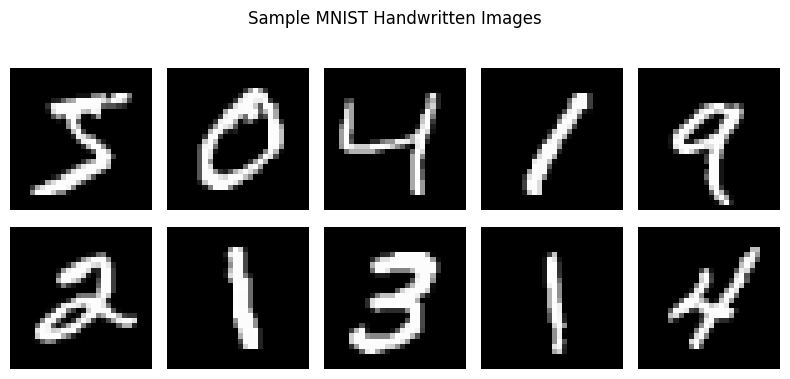

In [ ]:

import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(x, _), (_, _) = mnist.load_data()

plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x[i], cmap='gray', interpolation='nearest')
    plt.axis('off')

plt.suptitle("Sample MNIST Handwritten Images")
plt.tight_layout()
plt.show()


## Task iii: Build a Discriminator to classify images as real or generated and combine both models.

In [ ]:
discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(512),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dense(256),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dense(1, activation="sigmoid")
], name="Discriminator")

discriminator.summary()

# Combine Generator and Discriminator
discriminator.trainable = False

gan_input = layers.Input(shape=(noise_dim,))
generated_image = generator(gan_input)
gan_output = discriminator(generated_image)

gan = Model(gan_input, gan_output, name="Combined_GAN")
gan.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5),
    loss="binary_crossentropy"
)

discriminator.trainable = True

print("Generator, Discriminator and combined GAN are ready.")

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

Generator, Discriminator and combined GAN are ready.


## Task iv: Train the Generator and Discriminator alternately and plot their training losses.

The Discriminator is trained using real images (label 1) and generated images (label 0). The Generator is trained to make the Discriminator classify generated images as real (label 1).

Epoch 1/20 - D Loss: 0.5560 - G Loss: 1.0338
Epoch 2/20 - D Loss: 0.4646 - G Loss: 1.4870
Epoch 3/20 - D Loss: 0.4335 - G Loss: 1.5745
Epoch 4/20 - D Loss: 0.4828 - G Loss: 1.3875
Epoch 5/20 - D Loss: 0.4323 - G Loss: 1.6201
Epoch 6/20 - D Loss: 0.4039 - G Loss: 1.7175
Epoch 7/20 - D Loss: 0.3786 - G Loss: 1.7256
Epoch 8/20 - D Loss: 0.3826 - G Loss: 1.8104
Epoch 9/20 - D Loss: 0.4306 - G Loss: 1.6339
Epoch 10/20 - D Loss: 0.4154 - G Loss: 1.6293
Epoch 11/20 - D Loss: 0.3973 - G Loss: 1.6391
Epoch 12/20 - D Loss: 0.3853 - G Loss: 1.6942
Epoch 13/20 - D Loss: 0.3888 - G Loss: 1.7530
Epoch 14/20 - D Loss: 0.3807 - G Loss: 1.7244
Epoch 15/20 - D Loss: 0.3830 - G Loss: 1.7490
Epoch 16/20 - D Loss: 0.3826 - G Loss: 1.7380
Epoch 17/20 - D Loss: 0.3835 - G Loss: 1.7275
Epoch 18/20 - D Loss: 0.3753 - G Loss: 1.7313
Epoch 19/20 - D Loss: 0.3795 - G Loss: 1.7651
Epoch 20/20 - D Loss: 0.3676 - G Loss: 1.7715


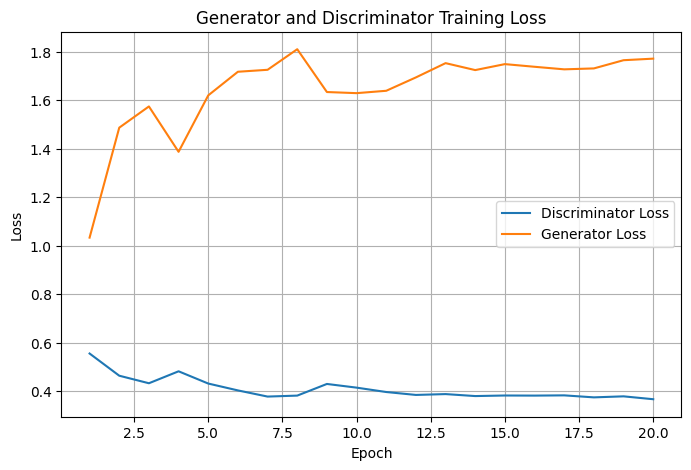

In [ ]:
for epoch in [5, 10, 15, 20]:

    noise = np.random.normal(0, 1, (10, 100))
    images = generator.predict(noise, verbose=0)

    plt.figure(figsize=(8, 3))

    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].squeeze(), cmap='gray')
        plt.axis('off')

    plt.suptitle(f'Epoch {epoch}')
    plt.show()

## Task v: Generate images at different training epochs and evaluate their recognizability and quality.
The following cell displays images generated by the trained Generator. Compare the images at different epochs using the saved model snapshots.

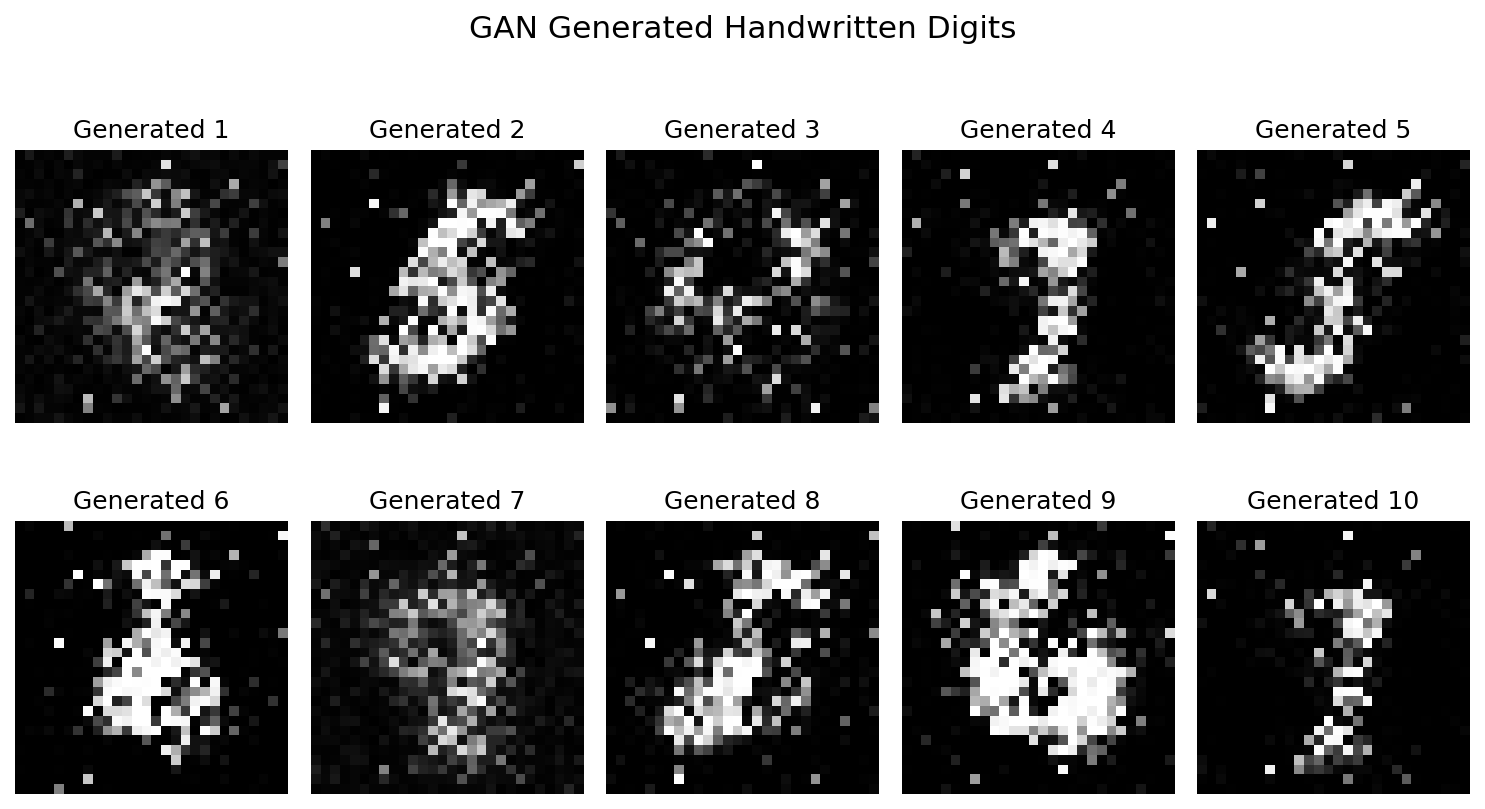

Generated images: (10, 28, 28, 1)
Image generation completed successfully.


In [ ]:

# Display GAN-generated images clearly

noise = tf.random.normal([10, noise_dim])
generated_images = generator(noise, training=False).numpy()

plt.figure(figsize=(10, 6), dpi=150)

for i in range(10):
    plt.subplot(2, 5, i + 1)

    img = generated_images[i].squeeze()
    img = (img + 1) / 2

    plt.imshow(img, cmap="gray", interpolation="nearest")
    plt.axis("off")
    plt.title(f"Generated {i+1}")

plt.suptitle("GAN Generated Handwritten Digits", fontsize=15)
plt.tight_layout()
plt.show()

print("Generated images:", generated_images.shape)
print("Image generation completed successfully.")


## Result
Thus, a GAN was developed using the MNIST dataset. The Generator and Discriminator were trained alternately, their training losses were plotted, and synthetic handwritten digit images were generated and visually evaluated.